In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
plt.rcParams['font.family']= 'NanumGothic' 
plt.rcParams['axes.unicode_minus']=False

In [ ]:
# 예측 목표:
이사 계획 있음(0) vs 없음(1) → 정착 지속 의지
→ 연령 기준으로 청년군 vs 중장년군 나눠서 따로 모델링

# 연령 구분:
청년층: 만 20~39세

중장년층: 만 40~64세

# 1. 예측 대상 (종속 변수)
| 컬럼명                                | 내용         | 목적                              |
| ---------------------------------- | ---------- | ------------------------------- |
| `문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?` | 1=있음, 2=없음 | **정착 지속 의사 (0=이사계획 있음 / 1=없음)** |


# 최종 정착 의지 판단 기준
| 조건                                            | 정착 의지 (1) vs 탈정착 (0)             |
| --------------------------------------------- | -------------------------------- |
| 현재 비수도권 & `문33=2` (이사 계획 없음)                  | ✅ 정착 지속 의지 있음 (1)                |
| 현재 비수도권 & `문33=1` (이사 계획 있음) + `Q35_1`이 수도권이면 | 🚫 수도권 이주 희망 → **탈정착 (0)**       |
| 현재 비수도권 & `문33=1` + `Q35_1`이 비수도권이면           | ✅ 여전히 비수도권 선호 → **정착 지속 간주 (1)** |


#  2. 기본 인구 특성 (설명 변수)
| 컬럼명                   | 설명                   |
| --------------------- | -------------------- |
| `문3. 현재주택에 살기 시작한 연도` | → 정착 기간 간접 추정 가능     |
| `문2. 가구주가 된 연도`       | → 주택 관련 의사결정 주체 기간   |
| `가구주 연령` (추가 필요)      | → 연령 필터링용 (청년 vs 중년) |
| `가구원수`                | → 생활 규모, 가족 구성 해석 가능 |
| `시도`                  | 수도권/비수도권 분류 기준       |


 3. 주거 조건/환경 변수
| 범주      | 주요 변수                    | 설명          |
| ------- | ------------------------ | ----------- |
| 주택유형    | `문4. 귀 댁의 주택 유형은 무엇입니까?` | 아파트/단독/연립 등 |
| 점유형태    | `문7. 귀 댁의 점유형태`          | 자가/전세/월세 등  |
| 자가보유    | `문8. 생애 최초 자가 여부`        | 자가주택 유무     |
| 현재주택 가격 | `문12. 현재 주택가격`           | 자산 가치 간접 지표 |


# 4. 만족도 관련 변수 (정성적 특성

| 범주        | 주요 문항 (문23/문24)           | 설명                     |
| --------- | ------------------------- | ---------------------- |
| 주택 상태 만족도 | 구조물, 난방, 채광, 환기 등 (문23.x) | 총 10개                  |
| 주거환경 만족도  | 교통, 의료, 교육, 치안 등 (문24.x)  | 총 14개                  |
| 종합 만족도    | `문25. 주택 전반 만족도`          | 회귀 예측 대상이나, 설명 변수로도 가능 |


# 5. 이사 관련 변수
| 컬럼명                    | 설명                  |
| ---------------------- | ------------------- |
| `문34-1. 이사 사유 (복수 응답)` | 경제, 일자리, 교육 등 이사 원인 |
| `문27. 직전 거주 시도`        | 수도권 → 비수도권 판별 가능    |


In [ ]:
# Re-import due to kernel reset
import pandas as pd

# Reload CSV
data_path = "2023_일반가구_20250526_59760.csv"
data_2023 = pd.read_csv(data_path, encoding='cp949', low_memory=False)

# 수도권 지역명 기준 정의
capital_regions = ['서울특별시', '경기도', '인천광역시']

# 기존 이사 계획 변수 확인 및 정착의지 생성
df_non_capital = data_2023[~data_2023['시도'].isin(capital_regions)].copy()

# 정착의지_보정 생성 함수 정의
def classify_settlement(row):
    move_plan = row.get('문33. 귀 가구는 다른 주택으로 이사할 계획이 있습니까?')
    future_move_region = str(row.get('귀 댁은 앞으로 어느 지역으로 이사할 계획입니까?')).strip()

    if move_plan == 2:
        return 1  # 이사 계획 없음 → 정착 지속
    elif move_plan == 1:
        if any(region in future_move_region for region in capital_regions):
            return 0  # 수도권 희망 → 탈정착
        else:
            return 1  # 비수도권 희망 → 정착 지속
    else:
        return None  # 무응답 등

# 적용
df_non_capital['정착의지_보정'] = df_non_capital.apply(classify_settlement, axis=1)

# 분포 확인
df_non_capital['정착의지_보정'].value_counts(dropna=False).to_dict()


{1.0: 57084, nan: 4176}





#
#


[RandomForest] Accuracy: 0.9641691152464904
[RandomForest] Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.77      0.84      1519
           1       0.97      0.99      0.98     10733

    accuracy                           0.96     12252
   macro avg       0.95      0.88      0.91     12252
weighted avg       0.96      0.96      0.96     12252

[RandomForest] Confusion Matrix:
 [[ 1170   349]
 [   90 10643]]
[RandomForest] ROC AUC: 0.990166913986857


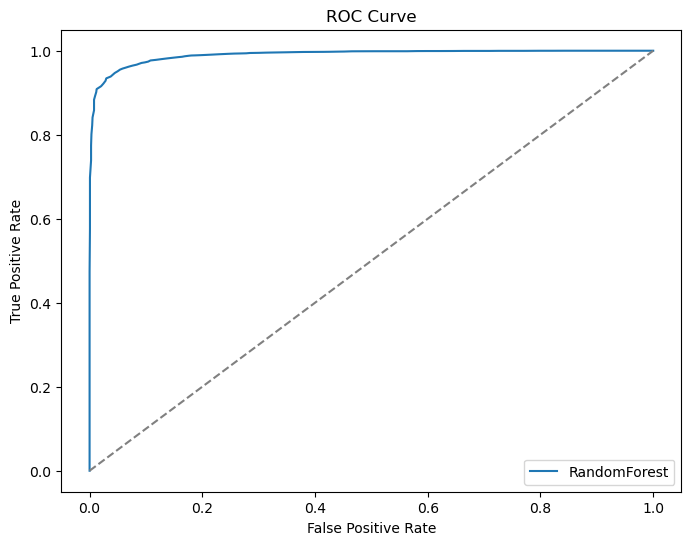

[Logistic Regression] Accuracy: 0.8826314071172053
[Logistic Regression] ROC AUC: 0.7509867710635315


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------
# 1. 데이터 불러오기
# ---------------------------------------------------
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding="cp949", low_memory=False)

# ---------------------------------------------------
# 2. 타겟 변수 생성: 수도권(서울11, 인천28, 경기41) vs 비수도권
# ---------------------------------------------------
metro = [11, 28, 41]
df['비수도권_정착'] = df['시도'].apply(lambda x: 0 if x in metro else 1)

# ---------------------------------------------------
# 3. 간단한 결측치 처리 예시 (필요시 수정)
# ---------------------------------------------------
# 예: 수치형 결측치는 0으로, 범주형은 "없음"으로
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(0)
df[cat_cols] = df[cat_cols].fillna("없음")

# ---------------------------------------------------
# 4. 필요없는 열 제외 + 타겟 변수 제외
# ---------------------------------------------------
X = df.drop(columns=['비수도권_정착', '시도'])
y = df['비수도권_정착']

# 범주형 변수 원핫 인코딩
X = pd.get_dummies(X, drop_first=True)

# ---------------------------------------------------
# 5. 학습/검증 데이터 분리
# ---------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------------------------
# 6. RandomForest 모델 학습
# ---------------------------------------------------
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 예측
y_pred_rf = rf.predict(X_test)

# ---------------------------------------------------
# 7. 평가: 정확도, confusion matrix, ROC AUC
# ---------------------------------------------------
print("[RandomForest] Accuracy:", accuracy_score(y_test, y_pred_rf))
print("[RandomForest] Classification Report:\n", classification_report(y_test, y_pred_rf))
print("[RandomForest] Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

# ROC AUC
y_prob_rf = rf.predict_proba(X_test)[:, 1]
print("[RandomForest] ROC AUC:", roc_auc_score(y_test, y_prob_rf))

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label='RandomForest')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# ---------------------------------------------------
# 8. 다른 모델 실험: Logistic Regression
# ---------------------------------------------------
logit = LogisticRegression(max_iter=1000)
logit.fit(X_train, y_train)
y_pred_logit = logit.predict(X_test)
print("[Logistic Regression] Accuracy:", accuracy_score(y_test, y_pred_logit))
print("[Logistic Regression] ROC AUC:", roc_auc_score(y_test, logit.predict_proba(X_test)[:,1]))


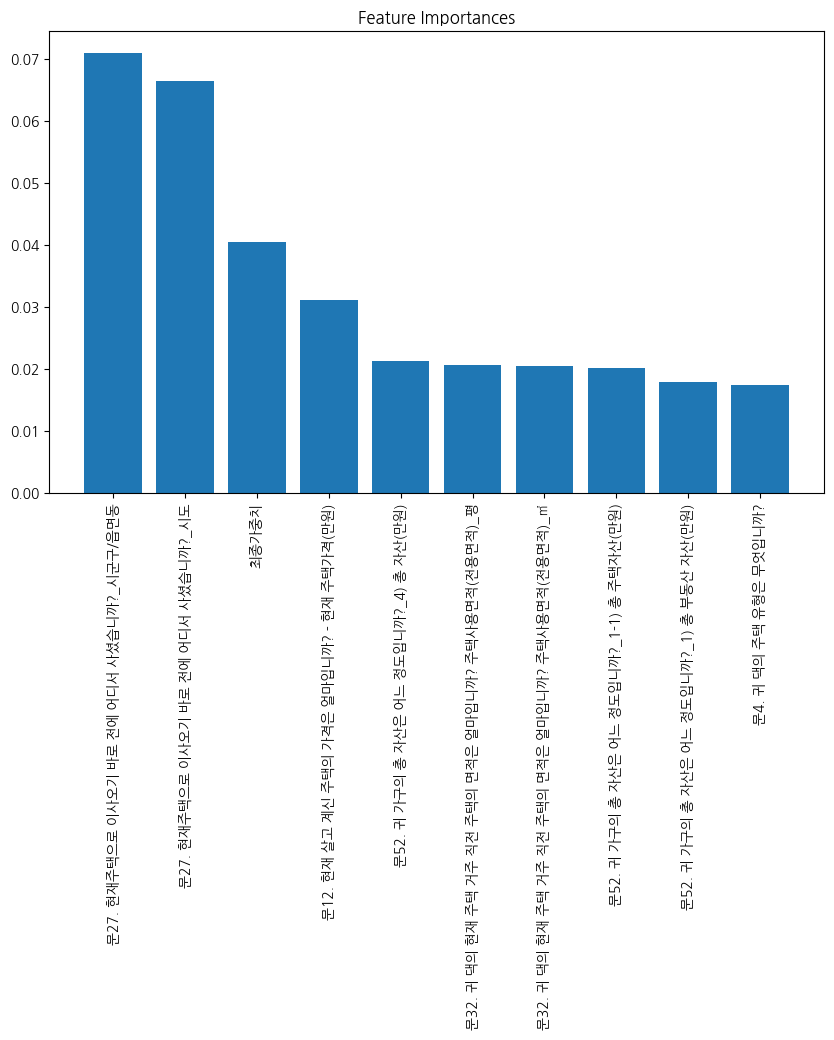

XGBoost: 0.9806562193927522
LightGBM: 0.9748612471433236
CatBoost: 0.980084884100555
DecisionTree: 0.945968005223637
SVM: 0.8758570029382958
KNN: 0.8873653281096964
RandomForest CV mean: 0.9236696049624552 std: 0.03500296601227416
Best Params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
SMOTE RandomForest Accuracy: 0.9609043421482207


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# 데이터 불러오기 및 전처리는 동일하다고 가정

# 1️⃣ Feature Importance
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10,6))
plt.title("Feature Importances")
plt.bar(range(10), importances[indices[:10]], align="center")
plt.xticks(range(10), [X.columns[i] for i in indices[:10]], rotation=90)
plt.show()

# 2️⃣ 다른 모델 실험
xgb_model = xgb.XGBClassifier(eval_metric='logloss')
xgb_model.fit(X_train, y_train)
print("XGBoost:", accuracy_score(y_test, xgb_model.predict(X_test)))

lgb_model = lgb.LGBMClassifier()
lgb_model.fit(X_train, y_train)
print("LightGBM:", accuracy_score(y_test, lgb_model.predict(X_test)))

cat_model = CatBoostClassifier(verbose=0)
cat_model.fit(X_train, y_train)
print("CatBoost:", accuracy_score(y_test, cat_model.predict(X_test)))

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
print("DecisionTree:", accuracy_score(y_test, dt.predict(X_test)))

svm = SVC()
svm.fit(X_train, y_train)
print("SVM:", accuracy_score(y_test, svm.predict(X_test)))

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
print("KNN:", accuracy_score(y_test, knn.predict(X_test)))

# 3️⃣ 교차검증
cv_scores = cross_val_score(rf, X, y, cv=5)
print("RandomForest CV mean:", np.mean(cv_scores), "std:", np.std(cv_scores))

# 4️⃣ 파라미터 튜닝
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
gs = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
gs.fit(X_train, y_train)
print("Best Params:", gs.best_params_)

# 5️⃣ SMOTE
smote = SMOTE()
X_res, y_res = smote.fit_resample(X_train, y_train)
rf_smote = RandomForestClassifier()
rf_smote.fit(X_res, y_res)
print("SMOTE RandomForest Accuracy:", accuracy_score(y_test, rf_smote.predict(X_test)))


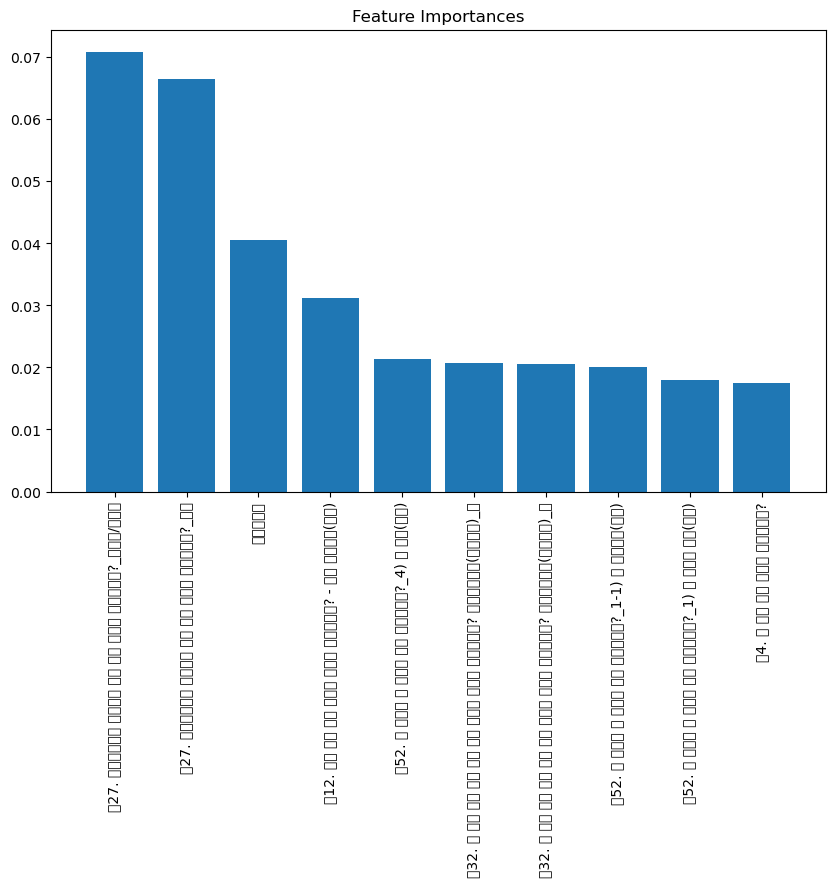

XGBoost: 0.9806562193927522
LightGBM: 0.9748612471433236
CatBoost: 0.980084884100555
DecisionTree: 0.9451518119490695


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# ---------------------------------------------------
# 데이터 불러오기 (예시)
# ---------------------------------------------------
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding="cp949", low_memory=False)

# ---------------------------------------------------
# 타겟 변수 생성: 수도권 코드 예시 [11,28,41] -> 비수도권 정착 1
# ---------------------------------------------------
metro = [11, 28, 41]
df['비수도권_정착'] = df['시도'].apply(lambda x: 0 if x in metro else 1)

# ---------------------------------------------------
# 결측치 처리 예시
# ---------------------------------------------------
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(0)
df[cat_cols] = df[cat_cols].fillna("없음")

# ---------------------------------------------------
# 변수 선택 / 인코딩
# ---------------------------------------------------
X = df.drop(columns=['비수도권_정착', '시도'])
y = df['비수도권_정착']

X = pd.get_dummies(X, drop_first=True)

# 특수문자 제거 (XGBoost 호환)
X.columns = X.columns.str.replace('[\\[\\]<>]', '_', regex=True)

# ---------------------------------------------------
# train/test split
# ---------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------------------------
# RandomForest 학습 및 Feature Importance
# ---------------------------------------------------
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10,6))
plt.title("Feature Importances")
plt.bar(range(10), importances[indices[:10]], align="center")
plt.xticks(range(10), [X.columns[i] for i in indices[:10]], rotation=90)
plt.show()

# ---------------------------------------------------
# 다른 모델 실험
# ---------------------------------------------------
xgb_model = xgb.XGBClassifier(eval_metric='logloss')
xgb_model.fit(X_train, y_train)
print("XGBoost:", accuracy_score(y_test, xgb_model.predict(X_test)))

lgb_model = lgb.LGBMClassifier()
lgb_model.fit(X_train, y_train)
print("LightGBM:", accuracy_score(y_test, lgb_model.predict(X_test)))

cat_model = CatBoostClassifier(verbose=0)
cat_model.fit(X_train, y_train)
print("CatBoost:", accuracy_score(y_test, cat_model.predict(X_test)))

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
print("DecisionTree:", accuracy_score(y_test, dt.predict(X_test)))

svm = SVC()
svm.fit(X_train, y_train)
print("SVM:", accuracy_score(y_test, svm.predict(X_test)))

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
print("KNN:", accuracy_score(y_test, knn.predict(X_test)))

# ---------------------------------------------------
# 교차검증
# ---------------------------------------------------
cv_scores = cross_val_score(rf, X, y, cv=5)
print("RandomForest CV mean:", np.mean(cv_scores), "std:", np.std(cv_scores))

# ---------------------------------------------------
# GridSearchCV로 파라미터 튜닝
# ---------------------------------------------------
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
gs = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
gs.fit(X_train, y_train)
print("Best Params:", gs.best_params_)

# ---------------------------------------------------
# SMOTE 오버샘플링
# ---------------------------------------------------
smote = SMOTE()
X_res, y_res = smote.fit_resample(X_train, y_train)
rf_smote = RandomForestClassifier()
rf_smote.fit(X_res, y_res)
print("SMOTE RandomForest Accuracy:", accuracy_score(y_test, rf_smote.predict(X_test)))


사용된 독립 변수 (입력 변수) 목록:
['동부/읍면부 구분', '문1. 귀하는 가구주나 가구주의 배우자이십니까?', '문2. 귀 댁의 가구주는 몇 년도부터 가구주가 되셨습니까?_년도', '문3. 귀 댁의 가구주께서는 가구주가 된 이후^ 언제부터 현재주택에 살았습니까?_년도', '문4. 귀 댁의 주택 유형은 무엇입니까?', '문6. 귀 댁의 주택 내 위치는 어디에 해당됩니까?', '문7. 귀 댁의 점유형태는 어디에 해당됩니까?', '문8. 귀 댁은 가구주께서 가구주가 된 이후에 지금까지 한 번이라도 자가주택을 마련한 적이 있습니까?', '문8-1. 귀 댁의 가구주는 가구주가 된 이후에 언제 생애최초로 주택을 마련 하셨습니까?_년도', '문8-2. 현재 거주하고 있는 주택이 생애최초로 마련한 주택입니까?', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_년', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_개월', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_총 개월', '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_평수', '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_㎡', '문9. 귀 가구는 지금 사는 곳 이외에 가구주나 가구원의 이름으로 보유한 주택이 있습니까?', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_년', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_개월', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_총 개월', '문10. 귀 댁의 가구주께서는 가구주가 된 이후 현재 주택을 언제 마련하셨습니까?_년도', '문11. 현재 살고 계신 주택을 어떻게 마련하셨습니까?', '문12. 현재 살고 계신 주택의 가격은 얼마입니까? - 현재 주택가격(만원)', '문12. 현재 살고 계신 주택의 가격은 얼마입니까? - 매입/증여/상속 당시 주택가격(만원)', '문13. 현재 살고 계

RandomForest Accuracy: 0.9641691152464904
Precision: 0.9682496360989811
Recall: 0.9916146464175906
F1 Score: 0.9797928653624857
ROC AUC: 0.990166913986857
Confusion Matrix:
 [[ 1170   349]
 [   90 10643]]


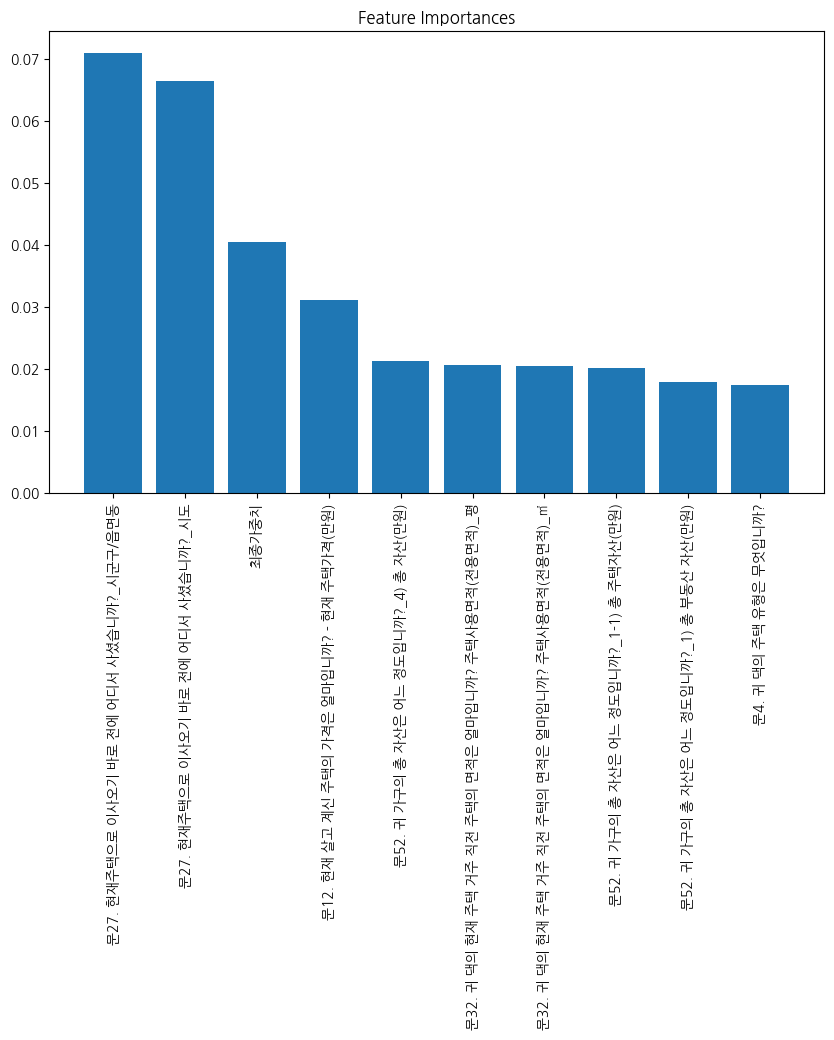

XGBoost Accuracy: 0.9806562193927522
XGBoost F1: 0.988978282100172
RandomForest CV mean: 0.9236696049624552 std: 0.03500296601227416
Best Params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
SMOTE RF Accuracy: 0.960822722820764
SMOTE Precision: 0.9707097603525847
SMOTE Recall: 0.9849995341470232
SMOTE F1: 0.9778024417314095


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# ---------------------------------------------------
# 데이터 불러오기 (예시)
# ---------------------------------------------------
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding="cp949", low_memory=False)

# ---------------------------------------------------
# 타겟 변수 생성
# ---------------------------------------------------
metro = [11, 28, 41]
df['비수도권_정착'] = df['시도'].apply(lambda x: 0 if x in metro else 1)

# ---------------------------------------------------
# 결측치 처리
# ---------------------------------------------------
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(0)
df[cat_cols] = df[cat_cols].fillna("없음")

# ---------------------------------------------------
# 변수 선택 / 인코딩
# ---------------------------------------------------
X = df.drop(columns=['비수도권_정착', '시도'])
y = df['비수도권_정착']

X = pd.get_dummies(X, drop_first=True)
X.columns = X.columns.str.replace('[\\[\\]<>]', '_', regex=True)

print("사용된 독립 변수 (입력 변수) 목록:")
print(X.columns.tolist())

# ---------------------------------------------------
# train/test split
# ---------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------------------------
# RandomForest 학습 및 Feature Importance
# ---------------------------------------------------
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 다양한 성능 지표 출력 함수
rf_pred = rf.predict(X_test)
print("RandomForest Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:,1]))
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10,6))
plt.title("Feature Importances")
plt.bar(range(10), importances[indices[:10]], align="center")
plt.xticks(range(10), [X.columns[i] for i in indices[:10]], rotation=90)
plt.show()

# ---------------------------------------------------
# 다른 모델 예시 (추가 지표 포함)
# ---------------------------------------------------
xgb_model = xgb.XGBClassifier(eval_metric='logloss')
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
print("XGBoost F1:", f1_score(y_test, xgb_pred))

# ---------------------------------------------------
# 교차검증
# ---------------------------------------------------
cv_scores = cross_val_score(rf, X, y, cv=5)
print("RandomForest CV mean:", np.mean(cv_scores), "std:", np.std(cv_scores))

# ---------------------------------------------------
# GridSearchCV
# ---------------------------------------------------
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
gs = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
gs.fit(X_train, y_train)
print("Best Params:", gs.best_params_)

# ---------------------------------------------------
# SMOTE
# ---------------------------------------------------
smote = SMOTE()
X_res, y_res = smote.fit_resample(X_train, y_train)
rf_smote = RandomForestClassifier()
rf_smote.fit(X_res, y_res)
y_smote_pred = rf_smote.predict(X_test)
print("SMOTE RF Accuracy:", accuracy_score(y_test, y_smote_pred))
print("SMOTE Precision:", precision_score(y_test, y_smote_pred))
print("SMOTE Recall:", recall_score(y_test, y_smote_pred))
print("SMOTE F1:", f1_score(y_test, y_smote_pred))

사용된 독립 변수 (입력 변수) 목록:
['동부/읍면부 구분', '문1. 귀하는 가구주나 가구주의 배우자이십니까?', '문2. 귀 댁의 가구주는 몇 년도부터 가구주가 되셨습니까?_년도', '문3. 귀 댁의 가구주께서는 가구주가 된 이후^ 언제부터 현재주택에 살았습니까?_년도', '문4. 귀 댁의 주택 유형은 무엇입니까?', '문6. 귀 댁의 주택 내 위치는 어디에 해당됩니까?', '문7. 귀 댁의 점유형태는 어디에 해당됩니까?', '문8. 귀 댁은 가구주께서 가구주가 된 이후에 지금까지 한 번이라도 자가주택을 마련한 적이 있습니까?', '문8-1. 귀 댁의 가구주는 가구주가 된 이후에 언제 생애최초로 주택을 마련 하셨습니까?_년도', '문8-2. 현재 거주하고 있는 주택이 생애최초로 마련한 주택입니까?', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_년', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_개월', '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_총 개월', '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_평수', '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_㎡', '문9. 귀 가구는 지금 사는 곳 이외에 가구주나 가구원의 이름으로 보유한 주택이 있습니까?', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_년', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_개월', '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_총 개월', '문10. 귀 댁의 가구주께서는 가구주가 된 이후 현재 주택을 언제 마련하셨습니까?_년도', '문11. 현재 살고 계신 주택을 어떻게 마련하셨습니까?', '문12. 현재 살고 계신 주택의 가격은 얼마입니까? - 현재 주택가격(만원)', '문12. 현재 살고 계신 주택의 가격은 얼마입니까? - 매입/증여/상속 당시 주택가격(만원)', '문13. 현재 살고 계

RandomForest Accuracy: 0.9643323539014038
RandomForest Precision: 0.9678298800436205
RandomForest Recall: 0.9922668405851114
RandomForest F1: 0.9798960298109215
RandomForest ROC AUC: 0.9908242604453652
RandomForest Confusion Matrix:
 [[ 1165   354]
 [   83 10650]]


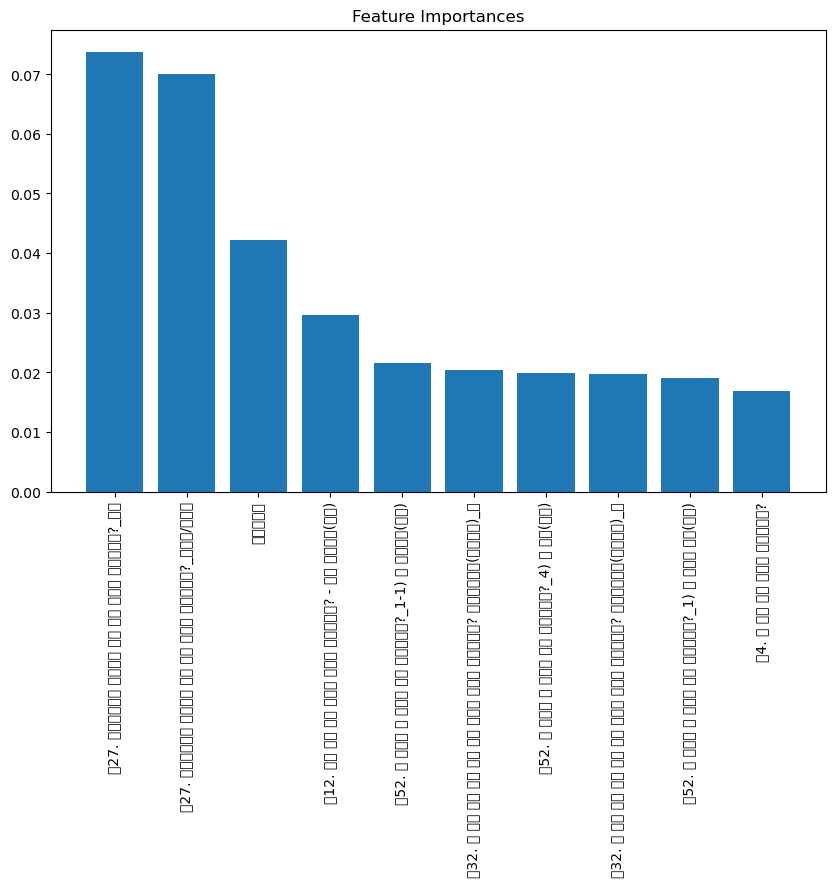

XGBoost Accuracy: 0.9806562193927522
XGBoost Precision: 0.9872794800371402
XGBoost Recall: 0.9906829404639895
XGBoost F1: 0.988978282100172
XGBoost ROC AUC: 0.9957537455162035
RandomForest CV mean: 0.9226412014365002 std: 0.034597946732338604
Best Params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
SMOTE RF Accuracy: 0.9606594841658505
SMOTE Precision: 0.9696692018693301
SMOTE Recall: 0.9859312401006243
SMOTE F1: 0.9777326064861869
SMOTE ROC AUC: 0.9861627558426826


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# ---------------------------------------------------
# 데이터 불러오기 (예시)
# ---------------------------------------------------
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding="cp949", low_memory=False)

# ---------------------------------------------------
# 타겟 변수 생성
# ---------------------------------------------------
metro = [11, 28, 41]
df['비수도권_정착'] = df['시도'].apply(lambda x: 0 if x in metro else 1)

# ---------------------------------------------------
# 결측치 처리
# ---------------------------------------------------
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(0)
df[cat_cols] = df[cat_cols].fillna("없음")

# ---------------------------------------------------
# 변수 선택 / 인코딩
# ---------------------------------------------------
X = df.drop(columns=['비수도권_정착', '시도'])
y = df['비수도권_정착']

X = pd.get_dummies(X, drop_first=True)
X.columns = X.columns.str.replace('[\\[\\]<>]', '_', regex=True)

print("사용된 독립 변수 (입력 변수) 목록:")
print(X.columns.tolist())

# ---------------------------------------------------
# train/test split
# ---------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------------------------
# RandomForest 학습 및 Feature Importance
# ---------------------------------------------------
rf = RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_split=2, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("RandomForest Accuracy:", accuracy_score(y_test, rf_pred))
print("RandomForest Precision:", precision_score(y_test, rf_pred))
print("RandomForest Recall:", recall_score(y_test, rf_pred))
print("RandomForest F1:", f1_score(y_test, rf_pred))
print("RandomForest ROC AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:,1]))
print("RandomForest Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10,6))
plt.title("Feature Importances")
plt.bar(range(10), importances[indices[:10]], align="center")
plt.xticks(range(10), [X.columns[i] for i in indices[:10]], rotation=90)
plt.show()

# ---------------------------------------------------
# XGBoost
# ---------------------------------------------------
xgb_model = xgb.XGBClassifier(eval_metric='logloss')
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
print("XGBoost Precision:", precision_score(y_test, xgb_pred))
print("XGBoost Recall:", recall_score(y_test, xgb_pred))
print("XGBoost F1:", f1_score(y_test, xgb_pred))
print("XGBoost ROC AUC:", roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]))

# ---------------------------------------------------
# 교차검증
# ---------------------------------------------------
cv_scores = cross_val_score(rf, X, y, cv=5)
print("RandomForest CV mean:", np.mean(cv_scores), "std:", np.std(cv_scores))

# ---------------------------------------------------
# GridSearchCV
# ---------------------------------------------------
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
gs = GridSearchCV(rf, param_grid, cv=3, n_jobs=-1)
gs.fit(X_train, y_train)
print("Best Params:", gs.best_params_)

# ---------------------------------------------------
# SMOTE
# ---------------------------------------------------
smote = SMOTE()
X_res, y_res = smote.fit_resample(X_train, y_train)
rf_smote = RandomForestClassifier()
rf_smote.fit(X_res, y_res)
y_smote_pred = rf_smote.predict(X_test)
print("SMOTE RF Accuracy:", accuracy_score(y_test, y_smote_pred))
print("SMOTE Precision:", precision_score(y_test, y_smote_pred))
print("SMOTE Recall:", recall_score(y_test, y_smote_pred))
print("SMOTE F1:", f1_score(y_test, y_smote_pred))
print("SMOTE ROC AUC:", roc_auc_score(y_test, rf_smote.predict_proba(X_test)[:,1]))


In [ ]:
# 모델 학습
rf = RandomForestClassifier(n_estimators=200)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print("RandomForest Accuracy:", accuracy_score(y_test, y_pred))
print("RandomForest Precision:", precision_score(y_test, y_pred))
print("RandomForest Recall:", recall_score(y_test, y_pred))
print("RandomForest F1:", f1_score(y_test, y_pred))
print("RandomForest ROC AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:,1]))
print("RandomForest Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# XGBoost 추가 지표
xgb_model = xgb.XGBClassifier(eval_metric='logloss')
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
print("XGBoost Precision:", precision_score(y_test, xgb_pred))
print("XGBoost Recall:", recall_score(y_test, xgb_pred))
print("XGBoost F1:", f1_score(y_test, xgb_pred))
print("XGBoost ROC AUC:", roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1]))

# SMOTE 후 RF
smote = SMOTE()
X_res, y_res = smote.fit_resample(X_train, y_train)
rf_smote = RandomForestClassifier()
rf_smote.fit(X_res, y_res)
y_smote_pred = rf_smote.predict(X_test)
print("SMOTE RF Accuracy:", accuracy_score(y_test, y_smote_pred))
print("SMOTE Precision:", precision_score(y_test, y_smote_pred))
print("SMOTE Recall:", recall_score(y_test, y_smote_pred))
print("SMOTE F1:", f1_score(y_test, y_smote_pred))
print("SMOTE ROC AUC:", roc_auc_score(y_test, rf_smote.predict_proba(X_test)[:,1]))


RandomForest Accuracy: 0.9651485471759713
RandomForest Precision: 0.9681140988372093
RandomForest Recall: 0.9929190347526321
RandomForest F1: 0.9803596890667403
RandomForest ROC AUC: 0.9906506159717218
RandomForest Confusion Matrix:
 [[ 1168   351]
 [   76 10657]]
XGBoost Accuracy: 0.9806562193927522
XGBoost Precision: 0.9872794800371402
XGBoost Recall: 0.9906829404639895
XGBoost F1: 0.988978282100172
XGBoost ROC AUC: 0.9957537455162035
SMOTE RF Accuracy: 0.9607411034933072
SMOTE Precision: 0.9692420358842915
SMOTE Recall: 0.9864902636727849
SMOTE F1: 0.9777900909636608
SMOTE ROC AUC: 0.9864321777255789


SVM Accuracy: 0.8758570029382958
SVM Precision: 0.8763686876940676
SVM Recall: 0.9992546352371192
SVM F1: 0.933786078098472
SVM ROC AUC: 0.7967930914156882
KNN Accuracy: 0.8873653281096964
KNN Precision: 0.9137397151198797
KNN Recall: 0.9622659088791577
KNN F1: 0.9373752042112906
KNN ROC AUC: 0.7963861524328597
LightGBM Accuracy: 0.9748612471433236
LightGBM Precision: 0.982772992497916
LightGBM Recall: 0.9886331873660673
LightGBM F1: 0.9856943799349744
LightGBM ROC AUC: 0.9947569918888832
CatBoost Accuracy: 0.980084884100555
CatBoost Precision: 0.9860969505978311
CatBoost Recall: 0.9912419640361502
CatBoost F1: 0.9886627636836726
CatBoost ROC AUC: 0.9954564153904576


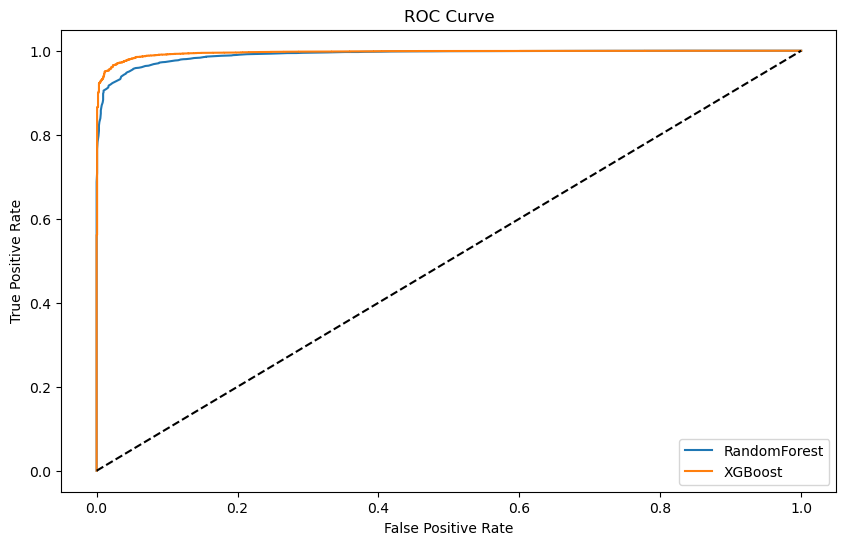

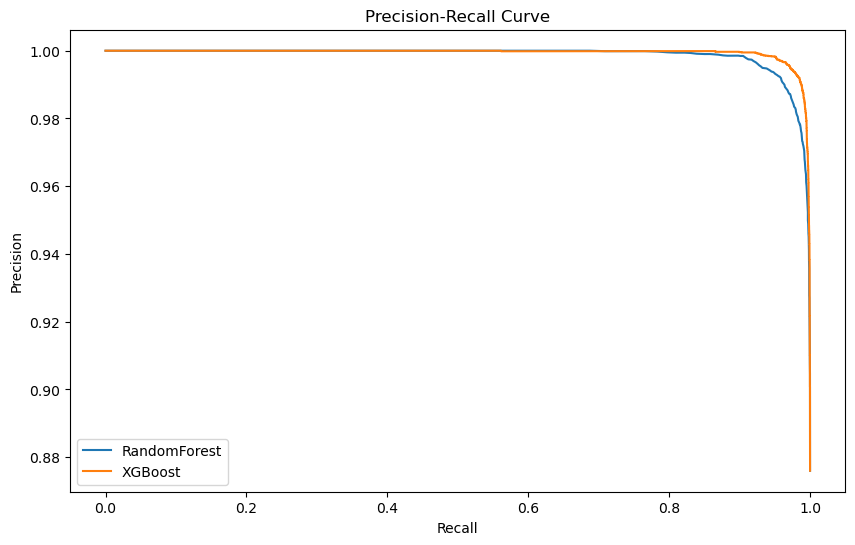

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# 데이터 불러오기 및 전처리 생략 (같음)
# ...




# ---------------------------------------------------
# train/test split
# ---------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# SVM
svm = SVC(probability=True)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("SVM Precision:", precision_score(y_test, svm_pred))
print("SVM Recall:", recall_score(y_test, svm_pred))
print("SVM F1:", f1_score(y_test, svm_pred))
print("SVM ROC AUC:", roc_auc_score(y_test, svm.predict_proba(X_test)[:,1]))

# KNN
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))
print("KNN Precision:", precision_score(y_test, knn_pred))
print("KNN Recall:", recall_score(y_test, knn_pred))
print("KNN F1:", f1_score(y_test, knn_pred))
print("KNN ROC AUC:", roc_auc_score(y_test, knn.predict_proba(X_test)[:,1]))

# LightGBM
lgbm = lgb.LGBMClassifier()
lgbm.fit(X_train, y_train)
lgbm_pred = lgbm.predict(X_test)
print("LightGBM Accuracy:", accuracy_score(y_test, lgbm_pred))
print("LightGBM Precision:", precision_score(y_test, lgbm_pred))
print("LightGBM Recall:", recall_score(y_test, lgbm_pred))
print("LightGBM F1:", f1_score(y_test, lgbm_pred))
print("LightGBM ROC AUC:", roc_auc_score(y_test, lgbm.predict_proba(X_test)[:,1]))

# CatBoost
catboost = CatBoostClassifier(verbose=0)
catboost.fit(X_train, y_train)
catboost_pred = catboost.predict(X_test)
print("CatBoost Accuracy:", accuracy_score(y_test, catboost_pred))
print("CatBoost Precision:", precision_score(y_test, catboost_pred))
print("CatBoost Recall:", recall_score(y_test, catboost_pred))
print("CatBoost F1:", f1_score(y_test, catboost_pred))
print("CatBoost ROC AUC:", roc_auc_score(y_test, catboost.predict_proba(X_test)[:,1]))

# ROC Curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf.predict_proba(X_test)[:,1])
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_model.predict_proba(X_test)[:,1])
plt.figure(figsize=(10,6))
plt.plot(fpr_rf, tpr_rf, label='RandomForest')
plt.plot(fpr_xgb, tpr_xgb, label='XGBoost')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve
prec_rf, rec_rf, _ = precision_recall_curve(y_test, rf.predict_proba(X_test)[:,1])
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, xgb_model.predict_proba(X_test)[:,1])
plt.figure(figsize=(10,6))
plt.plot(rec_rf, prec_rf, label='RandomForest')
plt.plot(rec_xgb, prec_xgb, label='XGBoost')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

# 데이터 예시
# df = pd.read_csv("your_data.csv")
# X = df.drop('target', axis=1)
# y = df['target']

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# SMOTE
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# RandomForest
rf = RandomForestClassifier(max_depth=10, n_estimators=200)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# XGBoost with Optuna
# study.best_params should be used; here, just an example:
xgb_model = xgb.XGBClassifier(max_depth=6, learning_rate=0.05, n_estimators=300,
                              subsample=0.8, colsample_bytree=0.8, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

# LightGBM
lgbm = lgb.LGBMClassifier(max_depth=8, n_estimators=300)
lgbm.fit(X_train, y_train)
lgbm_pred = lgbm.predict(X_test)

# CatBoost
catboost = CatBoostClassifier(depth=6, iterations=300, verbose=0)
catboost.fit(X_train, y_train)
catboost_pred = catboost.predict(X_test)

# SVM
svm = SVC(probability=True)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

# KNN
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

# 평가 지표 함수
def print_metrics(name, y_true, y_pred, y_proba):
    print(f"{name} Accuracy:", accuracy_score(y_true, y_pred))
    print(f"{name} Precision:", precision_score(y_true, y_pred))
    print(f"{name} Recall:", recall_score(y_true, y_pred))
    print(f"{name} F1:", f1_score(y_true, y_pred))
    print(f"{name} ROC AUC:", roc_auc_score(y_true, y_proba))

print_metrics('RandomForest', y_test, rf_pred, rf.predict_proba(X_test)[:,1])
print_metrics('XGBoost', y_test, xgb_pred, xgb_model.predict_proba(X_test)[:,1])
print_metrics('LightGBM', y_test, lgbm_pred, lgbm.predict_proba(X_test)[:,1])
print_metrics('CatBoost', y_test, catboost_pred, catboost.predict_proba(X_test)[:,1])
print_metrics('SVM', y_test, svm_pred, svm.predict_proba(X_test)[:,1])
print_metrics('KNN', y_test, knn_pred, knn.predict_proba(X_test)[:,1])

# Cross-Validation 요약
cv_results = {}
models = {'RandomForest': rf, 'XGBoost': xgb_model, 'LightGBM': lgbm, 'CatBoost': catboost}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_results[name] = {'Mean CV Accuracy': scores.mean(), 'Std': scores.std()}

cv_df = pd.DataFrame(cv_results).T
print(cv_df)

# ROC Curve & PR Curve
plt.figure(figsize=(10,5))
for name, model in models.items():
    y_score = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    plt.plot(fpr, tpr, label=name)
plt.plot([0,1],[0,1],'k--')
plt.title('ROC Curve')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
for name, model in models.items():
    y_score = model.predict_proba(X_test)[:,1]
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    plt.plot(recall, precision, label=name)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()


RandomForest Accuracy: 0.9463761018609207
RandomForest Precision: 0.9678677563150074
RandomForest Recall: 0.9710239448430076
RandomForest F1: 0.9694432817078276
RandomForest ROC AUC: 0.9730472617812194
XGBoost Accuracy: 0.9725759059745348
XGBoost Precision: 0.9831768751742727
XGBoost Recall: 0.9855585577191839
XGBoost F1: 0.9843662758235623
XGBoost ROC AUC: 0.993615575424725
LightGBM Accuracy: 0.9805746000652955
LightGBM Precision: 0.9880033479029108
LightGBM Recall: 0.9898444051057487
LightGBM F1: 0.9889230196406963
LightGBM ROC AUC: 0.9961107563458896
CatBoost Accuracy: 0.9755958210904342
CatBoost Precision: 0.9847611968035681
CatBoost Recall: 0.987421969626386
CatBoost F1: 0.9860897883228658
CatBoost ROC AUC: 0.9944708557286759
SVM Accuracy: 0.8294156056154097
SVM Precision: 0.9118459925664729
SVM Recall: 0.8914562564054784
SVM F1: 0.9015358522566663
SVM ROC AUC: 0.6730712812711095
KNN Accuracy: 0.780035912504081
KNN Precision: 0.9484490069180986
KNN Recall: 0.791950060560887
KNN F1

In [ ]:
# Cross-Validation 요약
cv_results = {}
models = {'RandomForest': rf, 'XGBoost': xgb_model, 'LightGBM': lgbm, 'CatBoost': catboost}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_results[name] = {'Mean CV Accuracy': scores.mean(), 'Std': scores.std()}

cv_df = pd.DataFrame(cv_results).T
print(cv_df)

# ROC Curve & PR Curve
plt.figure(figsize=(10,5))
for name, model in models.items():
    y_score = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    plt.plot(fpr, tpr, label=name)
plt.plot([0,1],[0,1],'k--')
plt.title('ROC Curve')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()
plt.show()

plt.figure(figsize=(10,5))
for name, model in models.items():
    y_score = model.predict_proba(X_test)[:,1]
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    plt.plot(recall, precision, label=name)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()


In [ ]:
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
import pandas as pd


plt.rcParams['font.family']= 'NanumGothic' 
plt.rcParams['axes.unicode_minus']=False

# ✅ 1. LightGBM 모델 학습
lgbm = lgb.LGBMClassifier(
    n_estimators=500,
    max_depth=7,
    learning_rate=0.05,
    random_state=42
)
lgbm.fit(X_train, y_train)

# ✅ 2. Feature Importance 시각화 (기본 Gain 기반)
importances = lgbm.feature_importances_
features = X_train.columns

importance_df = pd.DataFrame({
    'feature': features,
    'importance': importances
}).sort_values(by='importance', ascending=False)

# Figure size를 크게 설정
plt.figure(figsize=(12, 10))  # 가로 12인치, 세로 10인치 (필요에 따라 조절)
shap.summary_plot(shap_values, X_test, plot_size=(12, 10))
plt.barh(importance_df['feature'][:20][::-1], importance_df['importance'][:20][::-1])
plt.title('Top 20 Feature Importances (Gain)')
plt.xlabel('Importance')
plt.show()

# ✅ 3. SHAP Value 계산
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)

# ✅ 4. SHAP Summary Plot (전체 변수 영향력)
shap.summary_plot(shap_values, X_test)

# ✅ 5. SHAP Dependence Plot (특정 변수 하나 예시)
# 예: 가장 영향력이 큰 변수
top_feature = importance_df['feature'].iloc[0]
shap.dependence_plot(top_feature, shap_values, X_test)


In [ ]:
# ================================
# 📌 0) 라이브러리 불러오기
# ================================
import pandas as pd
import numpy as np
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, precision_recall_curve
)
from imblearn.over_sampling import SMOTE

# ================================
# 📌 1) 한글 폰트 (윈도우용)
# ================================
plt.rcParams['font.family'] = 'NanumGothic'  # 예: NanumGothic
plt.rcParams['axes.unicode_minus'] = False

# ================================
# 📌 2) 데이터 불러오기 & 간단 확인
# ================================
# ✅ 👉👉👉 여기에 너의 파일 경로!
df = pd.read_csv("2023_일반가구_20250526_59760.csv")  # 경로 수정

print(df.head())

# ================================
# 📌 3) X, y 분리 (타겟 컬럼명 맞게 수정!)
# ================================
X = df.drop('target', axis=1)   # 타겟컬럼명 'target' 대신 실제 컬럼명으로!
y = df['target']

# ================================
# 📌 4) Train-Test Split
# ================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ================================
# 📌 5) SMOTE로 클래스 불균형 보정
# ================================
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

print("Train shape:", X_train.shape)

# ================================
# 📌 6) LightGBM 모델 학습
# ================================
lgbm = lgb.LGBMClassifier(
    n_estimators=500,
    max_depth=7,
    learning_rate=0.05,
    random_state=42
)
lgbm.fit(X_train, y_train)

# ================================
# 📌 7) 성능 확인
# ================================
y_pred = lgbm.predict(X_test)
y_proba = lgbm.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))

# ================================
# 📌 8) Feature Importance Barplot 저장
# ================================
importances = lgbm.feature_importances_
features = X_train.columns

importance_df = pd.DataFrame({
    'feature': features,
    'importance': importances
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(12, 10))
plt.barh(importance_df['feature'][:20][::-1], importance_df['importance'][:20][::-1])
plt.title('Top 20 Feature Importances (Gain)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance_top20.png', dpi=300)
plt.show()

# ================================
# 📌 9) SHAP Value 계산
# ================================
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)

# ================================
# 📌 10) SHAP Summary Plot 저장
# ================================
shap.summary_plot(shap_values, X_test, show=False, plot_size=(12, 10))
plt.tight_layout()
plt.savefig('shap_summary_plot.png', dpi=300)
plt.show()

# ================================
# 📌 11) SHAP Dependence Plot 상위 3개
# ================================
top_features = importance_df['feature'].head(3)
for feature in top_features:
    shap.dependence_plot(
        feature, shap_values, X_test,
        show=True
    )
    plt.savefig(f'shap_dependence_{feature}.png', dpi=300)

# ================================
# 📌 12) 상관 Heatmap
# ================================
corr = X_train.corr()
plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

# ================================
# 📌 13) ROC Curve
# ================================
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_proba):.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=300)
plt.show()

# ================================
# 📌 14) Precision-Recall Curve
# ================================
precision, recall, _ = precision_recall_curve(y_test, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, lw=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.tight_layout()
plt.savefig('precision_recall_curve.png', dpi=300)
plt.show()


총 사용 변수 개수: 446
Train shape: (85790, 446)
LightGBM Accuracy: 0.9736369572314724
LightGBM Precision: 0.9836461624233414
LightGBM Recall: 0.9863039224820647
LightGBM F1: 0.9849732495929285
LightGBM ROC AUC: 0.9944668075000428


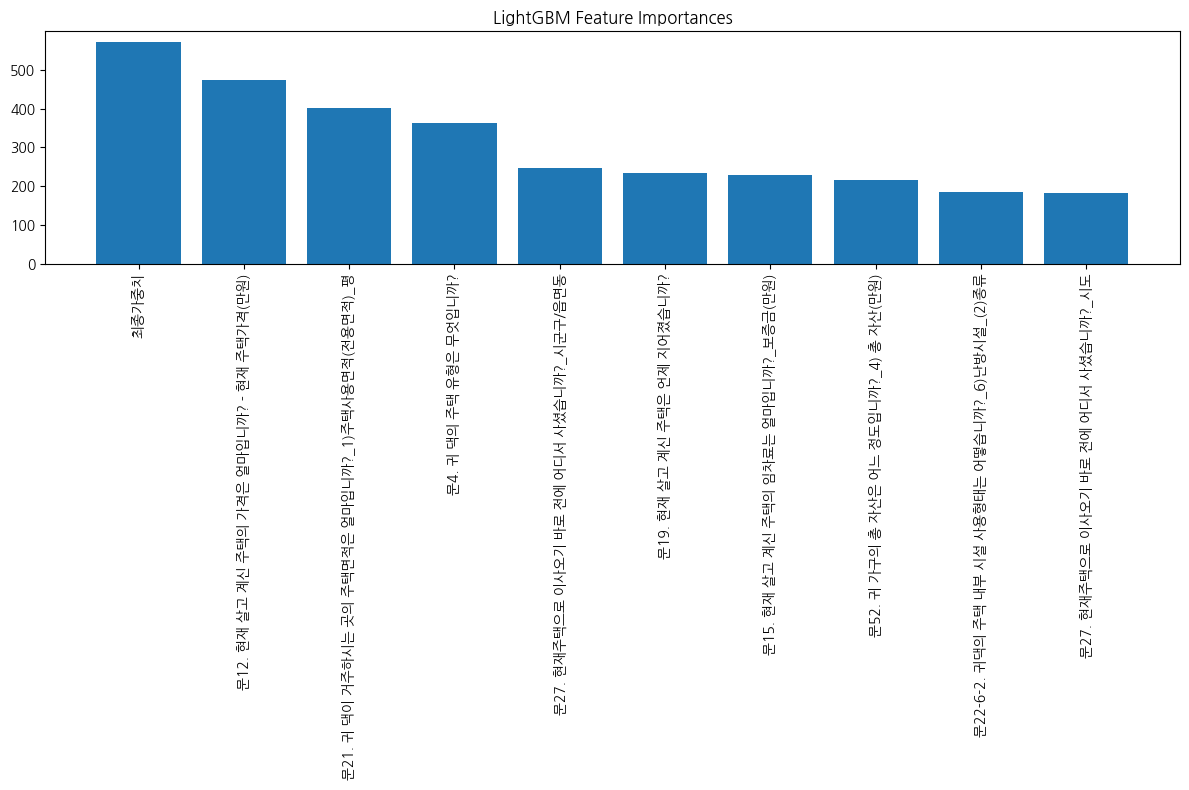

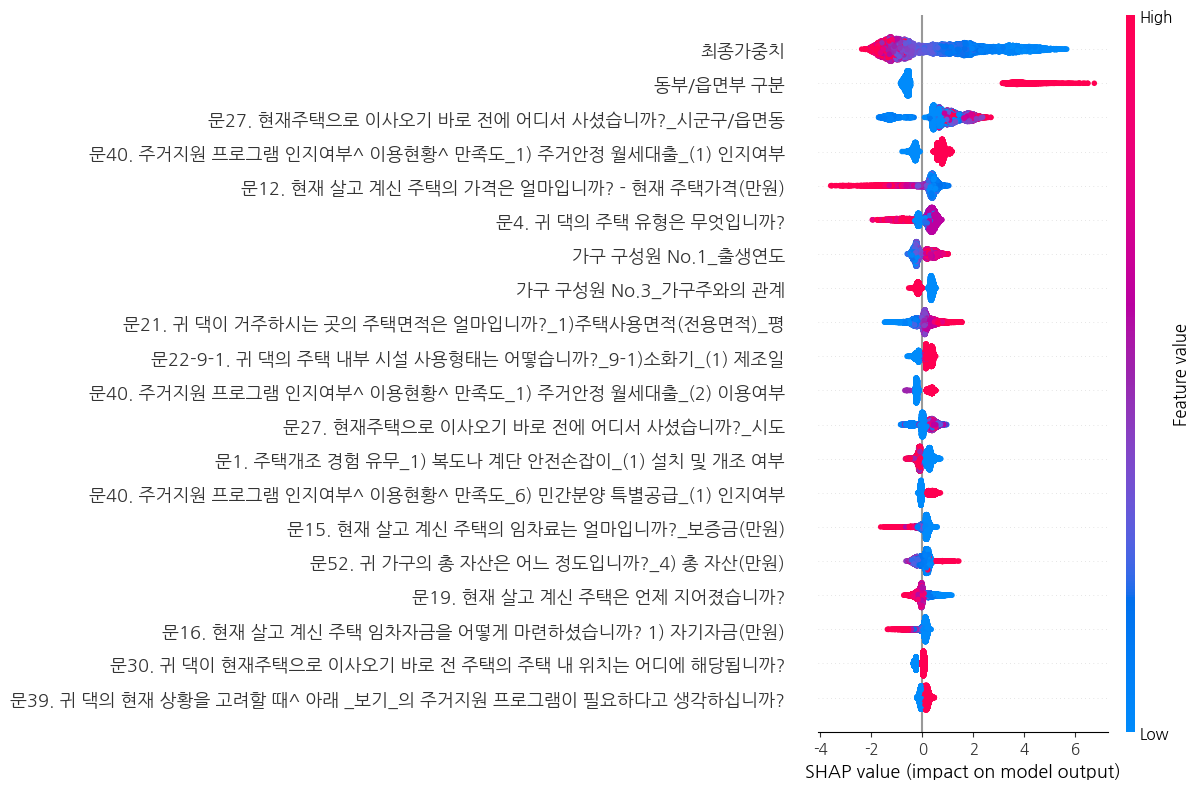

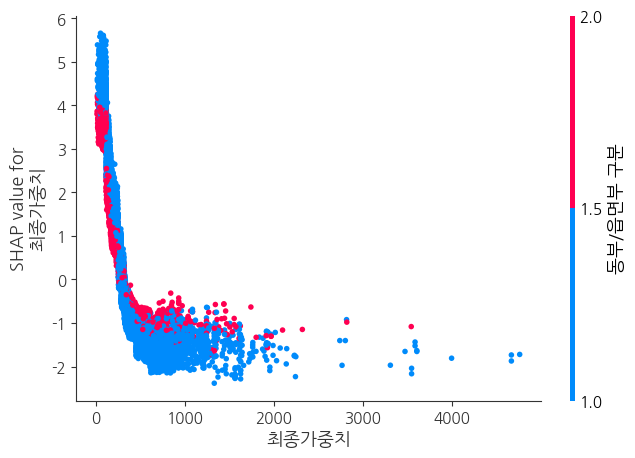

In [ ]:
# ===============================================
# 📌 1) 기본 라이브러리
# ===============================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
import lightgbm as lgb
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import shap

# ===============================================
# 📌 2) 데이터 불러오기 (경로만 맞게!)
# ===============================================
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding="cp949", low_memory=False)

# ===============================================
# 📌 3) 타겟 생성: 비수도권 정착 여부
# ===============================================
metro = [11, 28, 41]  # 서울, 인천, 경기 코드
df['비수도권_정착'] = df['시도'].apply(lambda x: 0 if x in metro else 1)

# ===============================================
# 📌 4) 결측치 처리
# ===============================================
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(0)
df[cat_cols] = df[cat_cols].fillna("없음")

# ===============================================
# 📌 5) 변수 선택 & 인코딩
# ===============================================
X = df.drop(columns=['비수도권_정착', '시도'])
y = df['비수도권_정착']

X = pd.get_dummies(X, drop_first=True)
X.columns = X.columns.str.replace('[\\[\\]<>]', '_', regex=True)

print(f"총 사용 변수 개수: {X.shape[1]}")

# ===============================================
# 📌 6) Train/Test Split + SMOTE
# ===============================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

print("Train shape:", X_train.shape)

# ===============================================
# 📌 7) LightGBM 모델 학습
# ===============================================
lgbm = lgb.LGBMClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    random_state=42
)

lgbm.fit(X_train, y_train)

y_pred = lgbm.predict(X_test)
y_proba = lgbm.predict_proba(X_test)[:, 1]

print("LightGBM Accuracy:", accuracy_score(y_test, y_pred))
print("LightGBM Precision:", precision_score(y_test, y_pred))
print("LightGBM Recall:", recall_score(y_test, y_pred))
print("LightGBM F1:", f1_score(y_test, y_pred))
print("LightGBM ROC AUC:", roc_auc_score(y_test, y_proba))

# ===============================================
# 📌 8) Feature Importance 시각화
# ===============================================
importances = lgbm.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 8))
plt.title("LightGBM Feature Importances")
plt.bar(range(10), importances[indices[:10]], align="center")
plt.xticks(range(10), [X.columns[i] for i in indices[:10]], rotation=90)
plt.tight_layout()
plt.show()

# ===============================================
# 📌 9) SHAP 값 계산 + 요약
# ===============================================
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, plot_size=(12, 8))

# Dependence Plot 예시
top_feature = X.columns[indices[0]]
shap.dependence_plot(top_feature, shap_values, X_test)


In [ ]:
top_features = importance_df['feature'].head(3)  # 상위 3개 변수

for feature in top_features:
    shap.dependence_plot(
        feature, shap_values, X_test,
        show=True  # 노트북이면 show=True
    )
    # 필요시 저장
    plt.savefig(f'shap_dependence_{feature}.png', dpi=300)


In [ ]:
import shap

# SHAP explainer (LightGBM)
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)

# Interaction 값 계산
interaction_values = shap.TreeExplainer(lgbm).shap_interaction_values(X_test)

# Interaction plot 예시 (변수 1 vs 변수 2)
shap.dependence_plot(
    ("최종가중치", "문21. 귀 댁이 거주하시는 곳의 주택면적은 얼마입니까?_1)주택사용면적(전용면적)_평"),
    interaction_values,
    X_test,
    display_features=X_test
)


In [ ]:
# LightGBM feature importance 상위 20개 변수만 선택
top_features = lgbm.feature_importances_.argsort()[-20:]
X_test_small = X_test.iloc[:, top_features].sample(500, random_state=42)

# TreeExplainer로 다시
explainer = shap.TreeExplainer(lgbm)
interaction_values = explainer.shap_interaction_values(X_test_small)

shap.dependence_plot(
    ("최종가중치", "문21. 귀 댁이 거주하시는 곳의 주택면적은 얼마입니까?_1)주택사용면적(전용면적)_평"),
    interaction_values,
    X_test_small
)


In [ ]:
from sklearn.inspection import plot_partial_dependence

# LightGBM wrapper 필요 (sklearn API)
lgbm_sklearn = lgb.LGBMClassifier().fit(X_train, y_train)

# 단일 변수 PDP
plot_partial_dependence(
    lgbm_sklearn, X_train,
    features=['최종가중치'],
    kind='average',
    grid_resolution=50
)

# 두 변수 PDP
plot_partial_dependence(
    lgbm_sklearn, X_train,
    features=[('최종가중치', '문21. 귀 댁이 거주하시는 곳의 주택면적은 얼마입니까?_1)주택사용면적(전용면적)_평')],
    kind='average',
    grid_resolution=30
)


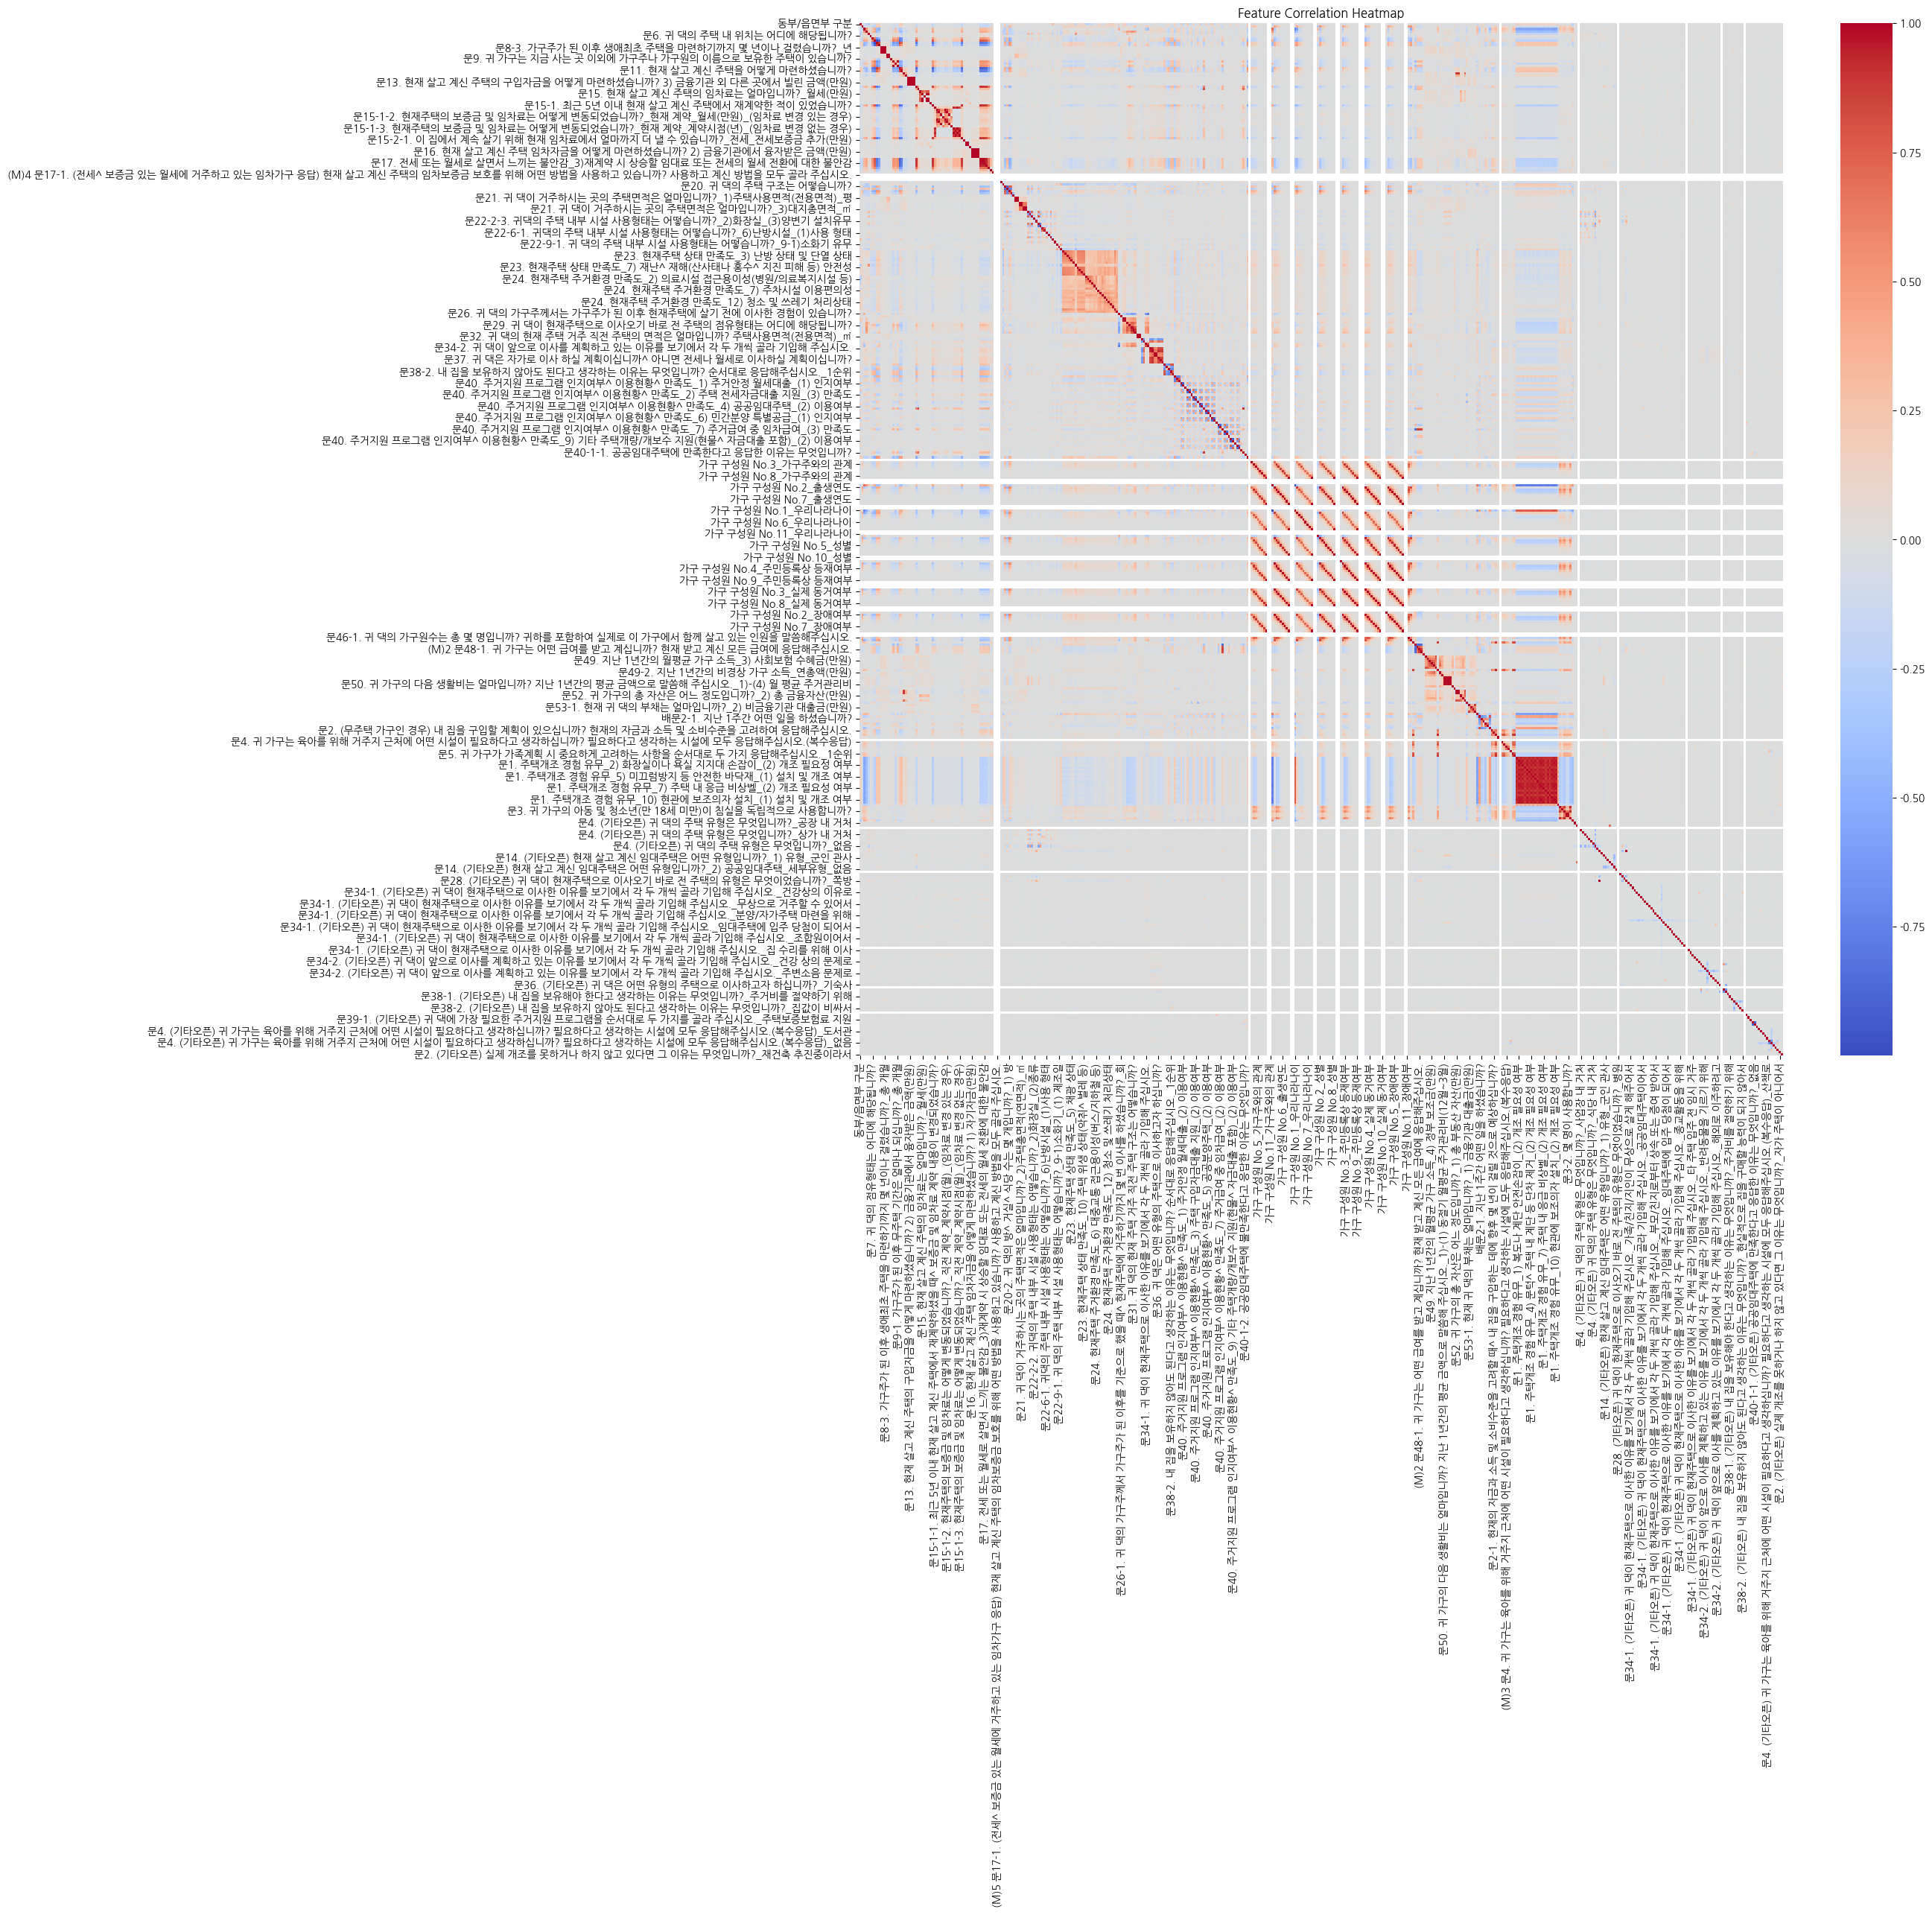

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 상관계수 계산
corr = X_train.corr()

plt.figure(figsize=(20, 18))
sns.heatmap(corr, cmap='coolwarm', annot=False)
plt.title('Feature Correlation Heatmap')
plt.show()


In [ ]:

# 학습/테스트 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

lgbm.fit(X_train, y_train)
import shap

explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)  # binary면 list
shap.dependence_plot(
    "최종가중치",
    shap_values[1],  # binary classification이면 1 클래스
    X_test,
    interaction_index="문21. 귀 댁이 거주하시는 곳의 주택면적은 얼마입니까?_1)주택사용면적(전용면적)_평"
)



In [ ]:
import shap


In [ ]:
 "인구주택총조사_2%_인구사항(제공)_2020.csv"
    "2023_일반가구_20250526_59760.csv"